# Movie Dataset Analysis (EDA)

This notebook analyzes `movie.csv` using Pandas, NumPy, Matplotlib, and Seaborn.

**Before running:** Keep `movie.csv` in the same folder as this notebook.

## 1. Import libraries

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Load the dataset

In [37]:
df = pd.read_csv("movie.csv")
df.head()

,S.No,movie_id,popularity,movie_title,original_title,language,release_date,vote_avg,vote_count
0,0,569094,3911.157,Spider-Man: Across the Spider-Verse,Spider-Man: Across the Spider-Verse,en,31-05-2023,8.5,3328
1,1,667538,2593.944,Transformers: Rise of the Beasts,Transformers: Rise of the Beasts,en,06-06-2023,7.5,2718
2,2,298618,2344.392,The Flash,The Flash,en,13-06-2023,7.0,2286
3,3,346698,2120.771,Barbie,Barbie,en,19-07-2023,7.5,2977
4,4,1006462,1969.340,The Flood,The Flood,en,14-07-2023,6.9,110


## 3. Dataset information

In [38]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
display(df.describe(include="all"))

Dataset shape: (10000, 9)

Column names:
['S.No', 'movie_id', 'popularity', 'movie_title', 'original_title', 'language', 'release_date', 'vote_avg', 'vote_count']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   S.No            10000 non-null  int64  
 1   movie_id        10000 non-null  int64  
 2   popularity      10000 non-null  float64
 3   movie_title     10000 non-null  str    
 4   original_title  10000 non-null  str    
 5   language        10000 non-null  str    
 6   release_date    9993 non-null   str    
 7   vote_avg        10000 non-null  float64
 8   vote_count      10000 non-null  int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 703.3 KB

Statistical summary:


,S.No,movie_id,popularity,movie_title,original_title,language,release_date,vote_avg,vote_count
count,10000.00000,1.000000e+04,10000.000000,10000,10000,10000,9993,10000.000000,10000.000000
unique,NaN,NaN,NaN,9723,9723,49,6026,NaN,NaN
top,NaN,NaN,NaN,The Three Musketeers,The Three Musketeers,en,15-08-2023,NaN,NaN
freq,NaN,NaN,NaN,4,4,7195,67,NaN,NaN
mean,4999.50000,3.037054e+05,35.759293,NaN,NaN,NaN,NaN,6.340260,1571.614300
std,2886.89568,3.424062e+05,91.696996,NaN,NaN,NaN,NaN,1.414885,2922.856516
min,0.00000,5.000000e+00,13.969000,NaN,NaN,NaN,NaN,0.000000,0.000000
25%,2499.75000,1.157325e+04,16.731000,NaN,NaN,NaN,NaN,5.900000,141.000000
50%,4999.50000,1.219210e+05,21.345000,NaN,NaN,NaN,NaN,6.600000,510.500000
75%,7499.25000,5.395570e+05,32.324500,NaN,NaN,NaN,NaN,7.100000,1604.250000


## 4. Check missing values

In [39]:
df.isnull().sum()

S.No              0
movie_id          0
popularity        0
movie_title       0
original_title    0
language          0
release_date      7
vote_avg          0
vote_count        0
dtype: int64

## 5. Remove duplicate rows

In [40]:
df = df.drop_duplicates().copy()
print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (10000, 9)


## 6. Clean the release date and missing values

The date parser below lets Pandas infer the date format, so it works with common CSV date formats. Numeric missing values are filled with their column median; text values are filled with their mode when available.

## 7. Top 10 most popular movies

In [55]:
if "release_date" in df.columns:
    df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

categorical_cols = df.select_dtypes(
    include=["object", "category", "str"]
).columns

for col in categorical_cols:
    mode_values = df[col].mode()
    if not mode_values.empty:
        df[col] = df[col].fillna(mode_values[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
S.No               0
movie_id           0
popularity         0
movie_title        0
original_title     0
language           0
release_date      14
vote_avg           0
vote_count         0
dtype: int64


In [42]:
top_movies = df.sort_values("popularity", ascending=False).head(10)
display(top_movies[["movie_title", "popularity"]])

,movie_title,popularity
0,Spider-Man: Across the Spider-Verse,3911.157
1,Transformers: Rise of the Beasts,2593.944
2,The Flash,2344.392
3,Barbie,2120.771
4,The Flood,1969.340
5,Insidious: The Red Door,1906.145
6,Meg 2: The Trench,1847.433
7,Operacja: Soulcatcher,1770.520
8,Hidden Strike,1549.911
9,No Hard Feelings,1520.294


## 8. Top 10 highest-rated movies (at least 100 votes)

In [43]:
top_rated = (
    df[df["vote_count"] >= 100]
    .sort_values("vote_avg", ascending=False)
    .head(10)
)
display(top_rated[["movie_title", "vote_avg", "vote_count"]])

,movie_title,vote_avg,vote_count
272,The Shawshank Redemption,8.7,24354
185,The Godfather,8.7,18431
872,Schindler's List,8.6,14408
2025,दिलवाले दुल्हनिया ले जायेंगे,8.6,4219
842,The Godfather Part II,8.6,11127
8861,Taylor Swift: The 1989 World Tour - Live,8.6,125
4044,Gabriel's Inferno,8.5,2353
561,七人の侍,8.5,3170
599,기생충,8.5,16194
427,千と千尋の神隠し,8.5,14713


## 9. Movie count by language

In [44]:
language_count = df["language"].value_counts()
display(language_count.head(10))

language
en    7195
ja     712
ko     416
fr     323
es     299
it     163
zh     161
cn     156
ru      93
de      82
Name: count, dtype: int64

## 10. Top 10 popular movies — bar chart

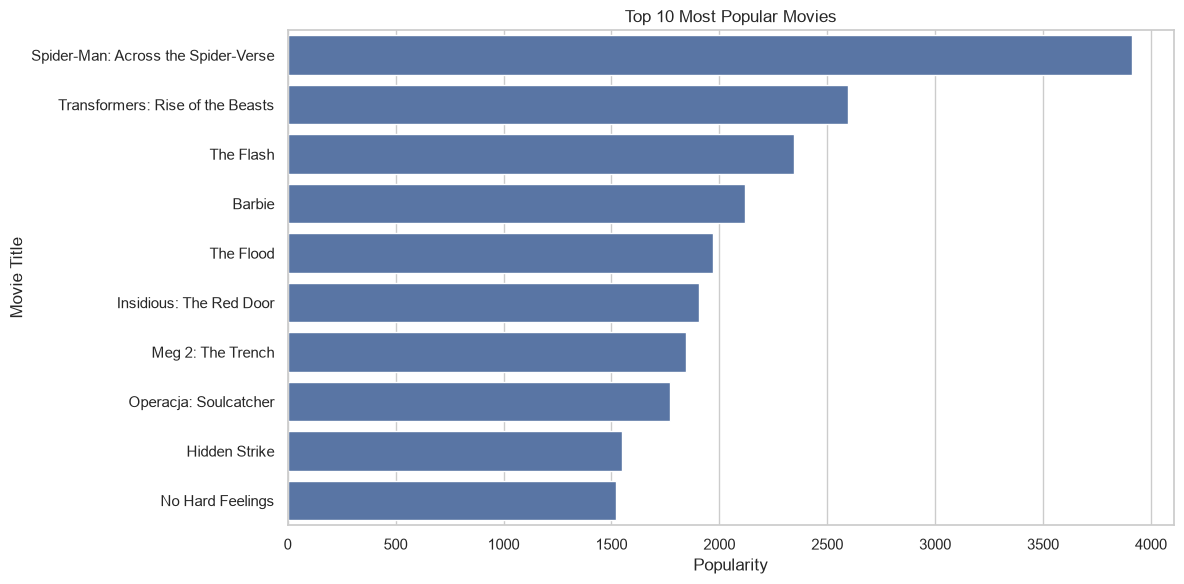

In [45]:
plt.figure(figsize=(12, 6))
sns.barplot(data=top_movies, x="popularity", y="movie_title")
plt.title("Top 10 Most Popular Movies")
plt.xlabel("Popularity")
plt.ylabel("Movie Title")
plt.tight_layout()
plt.show()

## 11. Distribution of movie ratings

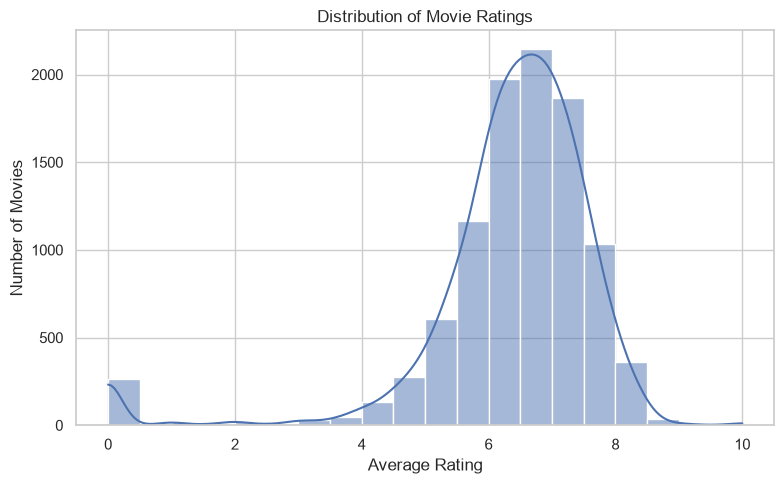

In [46]:
plt.figure(figsize=(8, 5))
sns.histplot(df["vote_avg"].dropna(), bins=20, kde=True)
plt.title("Distribution of Movie Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

## 12. Top 10 movie languages — bar chart

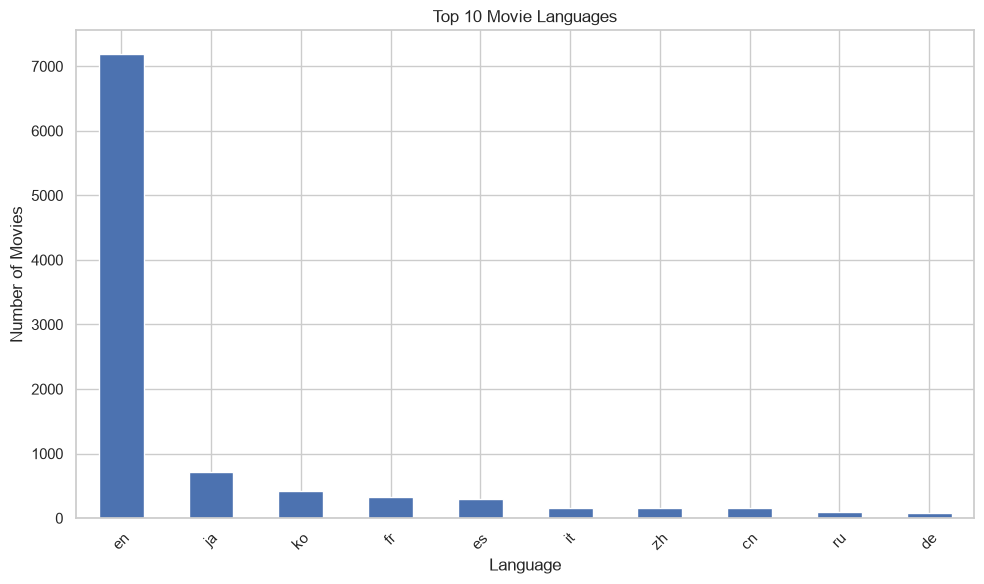

In [47]:
plt.figure(figsize=(10, 6))
language_count.head(10).plot(kind="bar")
plt.title("Top 10 Movie Languages")
plt.xlabel("Language")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 13. Correlation heatmap

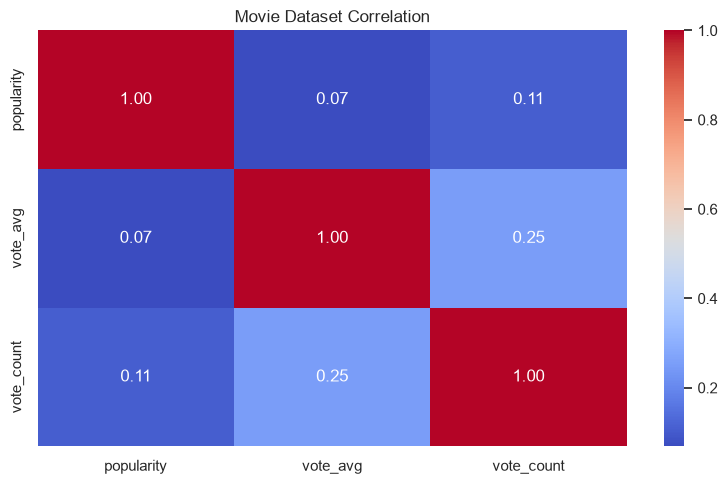

In [48]:
numeric_for_corr = df[["popularity", "vote_avg", "vote_count"]]
plt.figure(figsize=(8, 5))
sns.heatmap(numeric_for_corr.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Movie Dataset Correlation")
plt.tight_layout()
plt.show()

## 14. Total number of movies

In [49]:
print("Total movies:", len(df))

Total movies: 10000


## 15. Average movie rating

In [50]:
print("Average rating:", df["vote_avg"].mean())

Average rating: 6.34026


## 16. Most-voted movie

In [51]:
if not df["vote_count"].dropna().empty:
    most_voted = df.loc[df["vote_count"].idxmax()]
    print("Most voted movie:", most_voted["movie_title"])
    print("Vote count:", most_voted["vote_count"])
else:
    print("Vote count data is unavailable.")

Most voted movie: Inception
Vote count: 34241


## 17. Save the cleaned dataset

In [52]:
df.to_csv("cleaned_movie.csv", index=False)
print("Cleaned dataset saved as cleaned_movie.csv")

Cleaned dataset saved as cleaned_movie.csv
